In [17]:
from pathlib import Path
from matplotlib import pyplot as plt
from PIL import Image

from tqdm.auto import tqdm
import torch
import torchvision

image shape: (1024, 1024, 3)


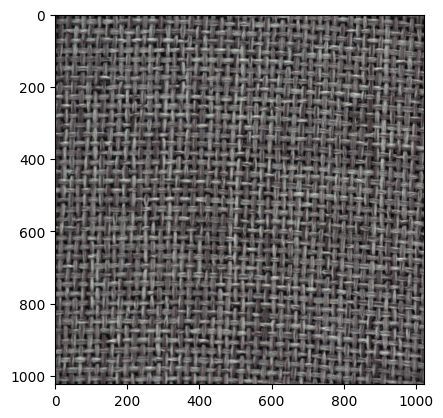

In [18]:

import cv2
imPath = Path(r"carpet\train\good\000.png")
# image = cv2.imread('carpet/train/good/000.png')
image = cv2.imread(imPath)
print('image shape:', image.shape)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)      # opencv default image is bgr,convert to rgb
plt.imshow(image_rgb)


torch.Size([3, 224, 224])


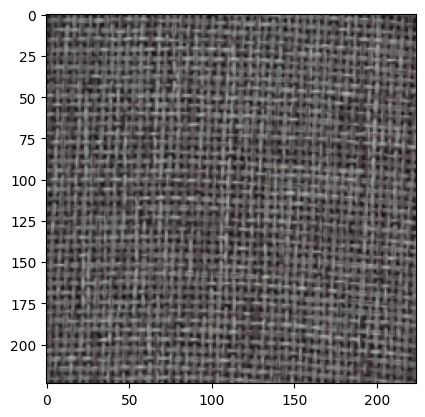

In [19]:
from torchvision.transforms import transforms

# Defining the transformation to resize the image and transform it to tensor
transform = transforms.Compose([
    transforms.Resize((224,224)),  
    transforms.ToTensor()          # Convert the PIL Image/NumPy Array to a PyTorch tensor and divide by 255.0
])
image_pil = Image.fromarray(image_rgb)      #Conver to PIL image for transformation to tensor
image_pil = transform(image_pil)
print (image_pil.size())

plt.imshow(image_pil.permute(1,2,0))        #put the channels as the last dimension

In [20]:
# Calculate the memory usage
memory_usage = image_pil.numel() * image_pil.element_size()
print(f"Memory usage of the tensor: {memory_usage * 279//1024} KB") # 279 samples in our dataset

Memory usage of the tensor: 164052 KB


In [21]:
from torchvision.datasets import ImageFolder
train_image_path = 'carpet/train'
good_dataset = ImageFolder(root=train_image_path, transform=transform)
x, y = good_dataset[3]

# Processed image
print("Image Shape:", x.shape)
print("Label:", y)


Image Shape: torch.Size([3, 224, 224])
Label: 0


In [22]:
import torch
from torch.utils.data import random_split, DataLoader

#split the data into train and test set
train_dataset, test_dataset = random_split(good_dataset, [0.8, 0.2])

print("Original dataset:", len(good_dataset))
print("Training subset:", len(train_dataset))
print("Testing subset:", len(test_dataset))

#Dataloaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Get a batch of images and labels from the training loader
image_batch, label_batch = next(iter(train_loader))

print(f'Shape of input images: {image_batch.shape}')
print(f'Shape of labels: {label_batch.shape}')

memory_usage = image_batch.numel() * image_batch.element_size()

print(f"Memory usage of the tensor: {memory_usage//1024} KB")


Original dataset: 280
Training subset: 224
Testing subset: 56
Shape of input images: torch.Size([32, 3, 224, 224])
Shape of labels: torch.Size([32])
Memory usage of the tensor: 18816 KB


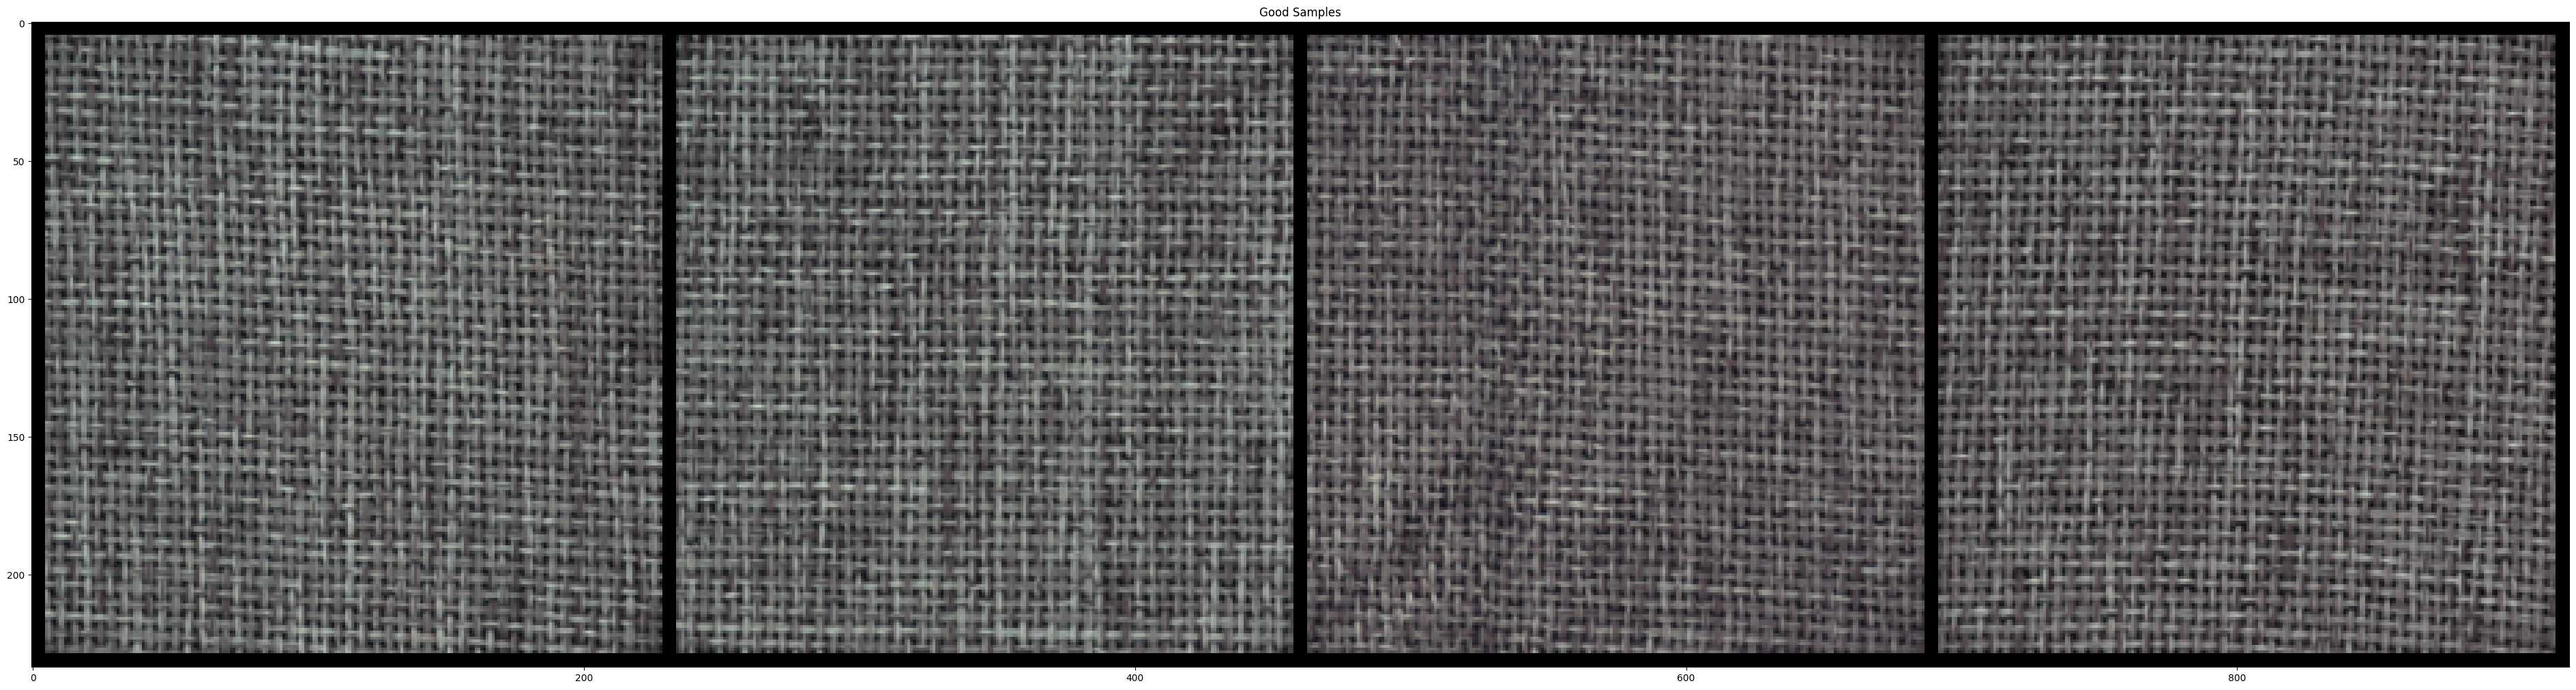

In [23]:
# Set the figure size
plt.figure(figsize=(12*4, 8*4))

# Create a grid of images from the image batch and visualize it
grid = torchvision.utils.make_grid(image_batch[0:4], padding=5, nrow=4)
plt.imshow(grid.permute(1, 2, 0))  # Permute dimensions to (height, width, channels) for visualization
plt.title('Good Samples')  # Set the title of the plot
plt.show()  # Show the plot

In [24]:
# import torch.nn.functional as F
# from torch import nn

# input_image = cv2.imread(r'carpet\train\good\000.png')
# print('image shape:', image.shape)
# image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)      # opencv default image is bgr,convert to rgb
# image_pil = Image.fromarray(image_rgb)                  # convert to pil image for transformation
# input_image = transform(image_pil)                      # resizes the image, converts to a tensor 
# # print(input_image.shape)
# # plt.imshow(input_image.permute(1,2,0))
# # plt.show()

# input_image = input_image.unsqueeze(0)                  # adds an extra dimension (represnting batch size)
# print('Input image shape', input_image.shape)

# c1 = nn.Conv2d(in_channels=3, out_channels=128, kernel_size=4)
# x = c1(input_image)
# print(x.shape)
# ap1 = nn.AvgPool2d(kernel_size=2, stride=2 )
# x = ap1(x)
# print(x.shape)
# c2 = nn.Conv2d(in_channels=128, out_channels=256, kernel_size=4)
# ap2 = nn.AvgPool2d(kernel_size=2, stride=2 )
# x= ap2(c2(x))
# print(x.shape)
# c3 = nn.Conv2d(in_channels=256, out_channels=256, kernel_size=3 )
# ap3 = nn.AvgPool2d(kernel_size=2, stride=2 )
# x = ap3(c3(x))
# print(x.shape)

# c4 = nn.ConvTranspose2d(in_channels=256, out_channels=256, kernel_size=4, stride=2, output_padding=1 )
# x = c4(x)
# print(x.shape)
# c5 = nn.ConvTranspose2d(in_channels=256, out_channels=128, kernel_size=5, stride=2, output_padding=1 )
# x = c5(x)
# print(x.shape)
# c6 = nn.ConvTranspose2d(in_channels=128, out_channels=3, kernel_size=5, stride=2, output_padding=1 )
# x = c6(x)
# print(x.shape)

Model

In [25]:
import torch
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(3, 128, kernel_size=4),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(128, 256, kernel_size=4),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
            nn.Conv2d(256, 256, kernel_size=3),
            nn.ReLU(),
            nn.AvgPool2d(kernel_size=2, stride=2),
        )
        self.decoder = nn.Sequential(
            nn.ConvTranspose2d(256, 256, kernel_size=4, stride=2, output_padding=1 ),
            nn.ReLU(),
            nn.ConvTranspose2d(256, 128, kernel_size=5, stride=2, output_padding=1),
            nn.ReLU(),
            nn.ConvTranspose2d(128, 3, kernel_size=5, stride=2, output_padding=1),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

# Test the autoencoder architecture
model = Autoencoder()  
input_image = torch.randn(1, 3, 224, 224)  # Sample input image
output_image = model(input_image)
print(output_image.shape)  # Print the shape of the output image


torch.Size([1, 3, 224, 224])


In [26]:
import torch.optim as optim

# Define loss function and optimizer
criterion = nn.MSELoss()  # Measures reconstruction error
optimizer = optim.Adam(model.parameters(), lr=0.001)



Training

In [27]:
# # Define a list to store training loss and validation loss
# Loss = []
# Validation_Loss = []


# num_epochs = 2
# for epoch in tqdm(range(num_epochs)):
#     model.train()  # Set model to training mode
#     for img, _ in train_loader:
#         # img = img.cuda()
        
#         output = model(img)
#         loss = criterion(output, img)

#         optimizer.zero_grad() #clears the gradients of all optimized tensors.  This step is necessary because gradients are accumulated by default in PyTorch, and we want to compute fresh gradients for the current batch of data.
#         loss.backward() # This line computes the gradients of the loss function with respect to the model parameters. These gradients are used to update the model parameters during optimization.
#         optimizer.step() # This line updates the model parameters using the computed gradients. 
#     Loss.append(loss.item())
       

#     # Calculate validation loss
#     model.eval()  # Set model to evaluation mode
#     with torch.no_grad():
#         val_loss_sum = 0.0
#         num_batches = 0
#         for img, _ in test_loader:
#             # img = img.cuda()
#             output = model(img)
#             val_loss = criterion(output, img)
#             val_loss_sum += val_loss.item()
#             num_batches += 1
#         val_loss_avg = val_loss_sum / num_batches
#         Validation_Loss.append(val_loss_avg)
    
#     if epoch % 5 == 0:
#         print('Epoch [{}/{}], Loss: {:.4f}, Validation Loss: {:.4f}'.format(epoch + 1, num_epochs, loss.item(), val_loss_avg))
# plt.plot(Loss, label='Training Loss')
# plt.plot(Validation_Loss, label='Validation Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()
# plt.show()

In [28]:
# plt.plot(Loss, label='Training Loss')
# plt.plot(Validation_Loss, label='Validation Loss')
# plt.xlabel('Epoch')
# plt.ylabel('Loss')
# plt.legend()
# plt.show()

In [29]:
# Save the model
# torch.save(model.state_dict(), 'autoencoder_loss.pth')
# model.eval()

# Loading the saved weight
ckpoints = torch.load('simple_autoencoder_l2_loss.pth', map_location=torch.device('cpu'))
model.load_state_dict(ckpoints)

C:\Users\uzair\AppData\Local\Temp\ipykernel_5008\3885791324.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ckpoints = torch.load('simple_autoencoder_l2_loss.pth', map_l

<All keys matched successfully>

Reconstruction of Good images

torch.Size([32, 224, 224])


<Figure size 1600x1200 with 0 Axes>

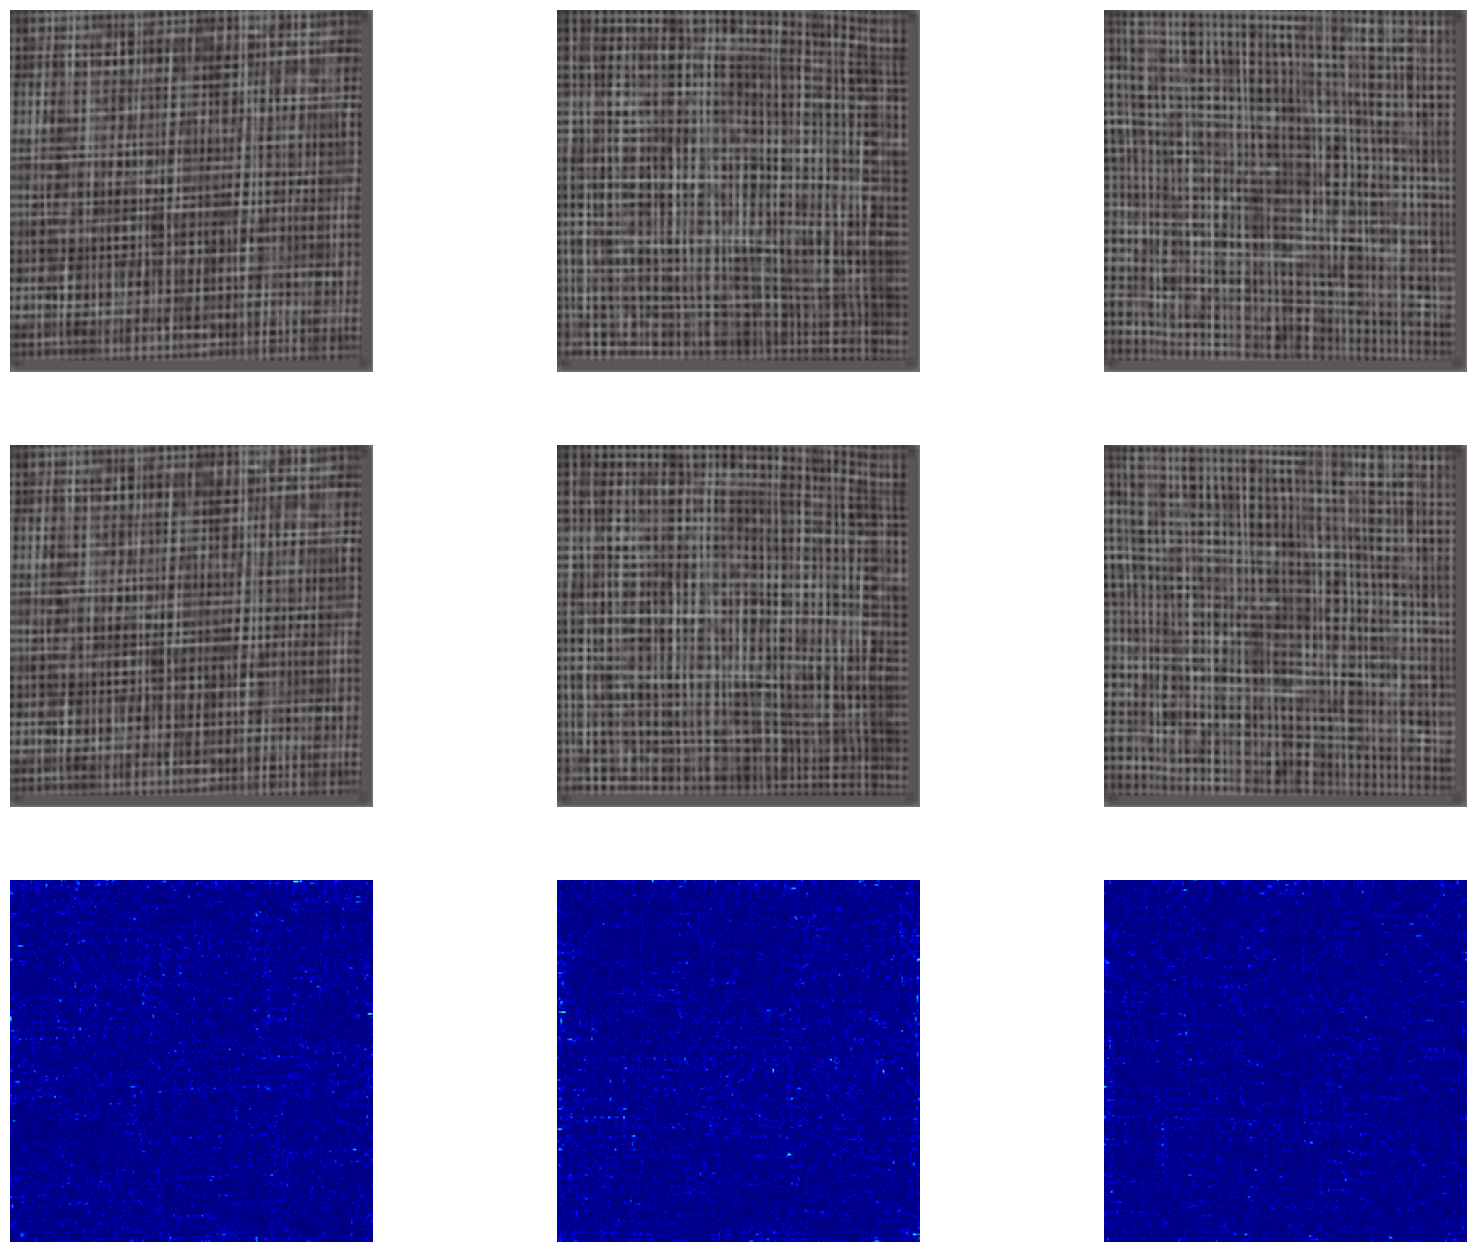

In [32]:
import torch
with torch.no_grad():
    for data, _ in train_loader:
        recon = model(data)
        break

recon_error=  ((data-recon)**2).mean(axis=1)
print(recon_error.shape)
plt.figure(dpi=250)
fig, ax = plt.subplots(3, 3, figsize=(5*4, 4*4))
for i in range(3):
    ax[0, i].imshow(recon[i].cpu().numpy().transpose((1, 2, 0)))
    ax[1, i].imshow(recon[i].cpu().numpy().transpose((1, 2, 0)))
    ax[2, i].imshow(recon_error[i][0:-10,0:-10].cpu().numpy(), cmap='jet',vmax= torch.max(recon_error[i])) #[0:-10,0:-10]
    ax[0, i].axis('OFF')
    ax[1, i].axis('OFF')
    ax[2, i].axis('OFF')
plt.show()

Reconstruction of Bad Images and their Heat Map

<Figure size 1600x1200 with 0 Axes>

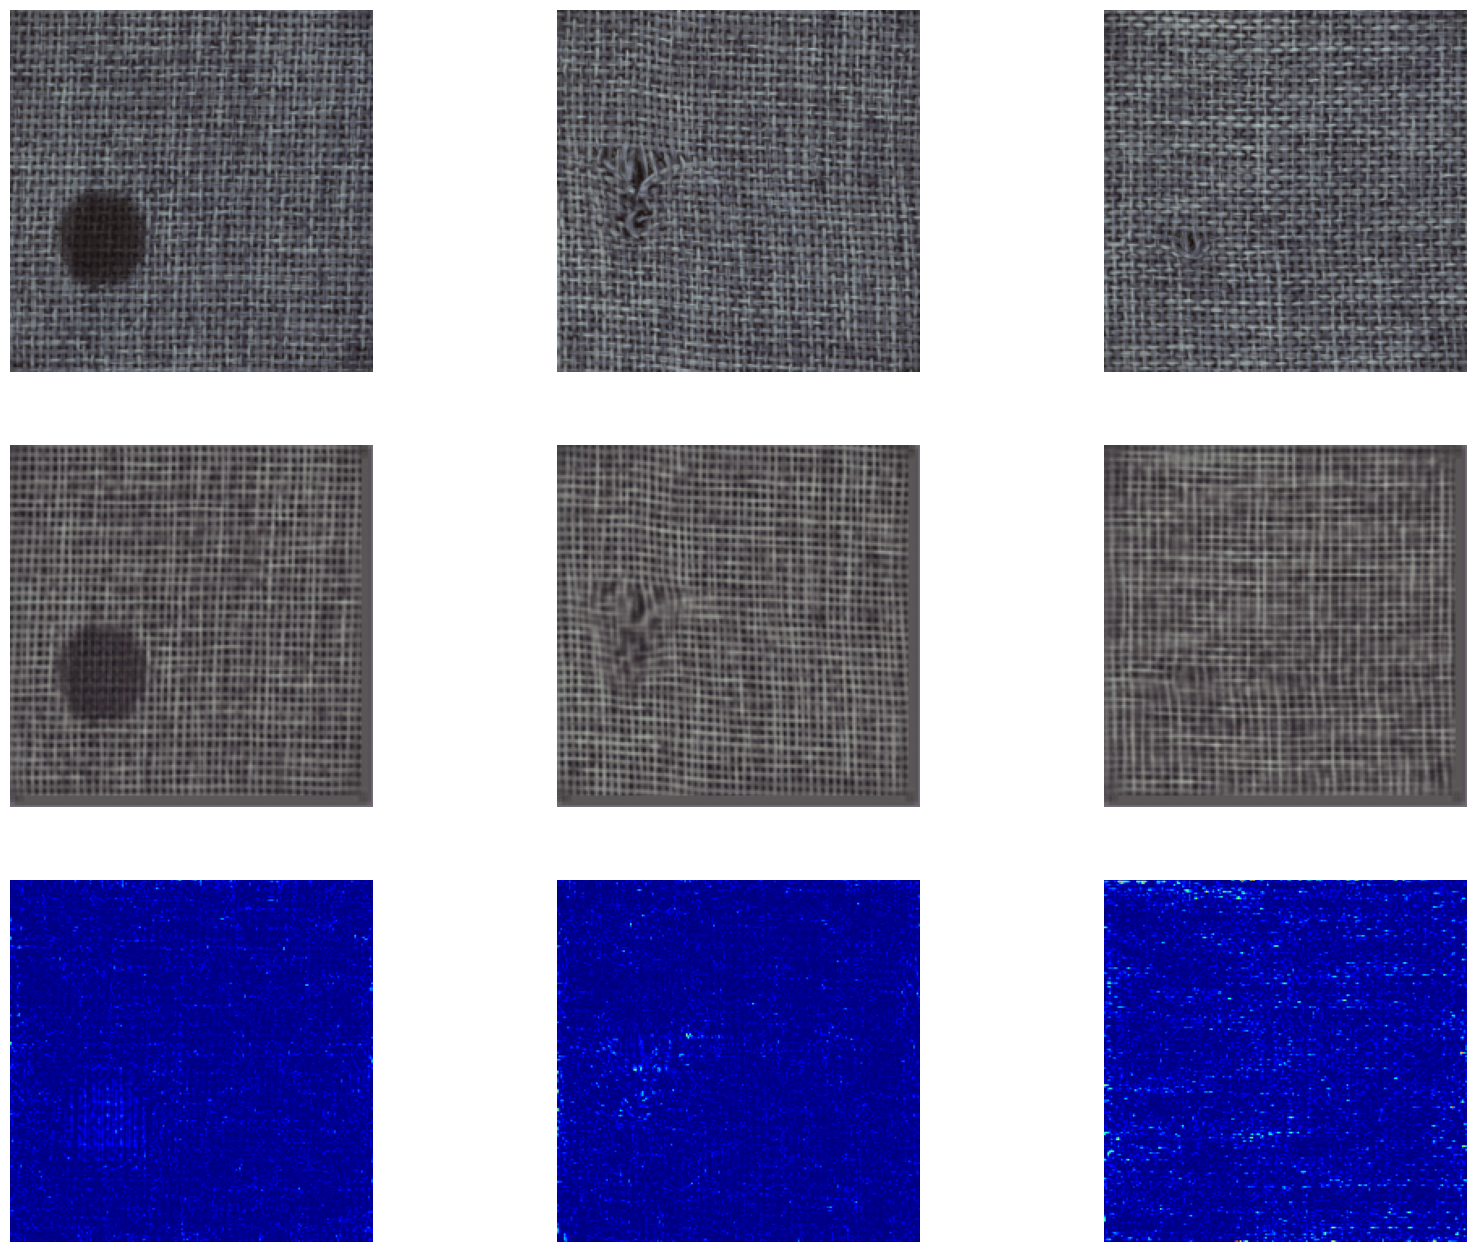

In [33]:
# Convert to PIL Image and transform
test_image_1 = transform(Image.fromarray(cv2.imread(r'carpet\test\color\000.png')))
test_image_2 = transform(Image.fromarray(cv2.imread(r'carpet\test\cut\000.png')))
test_image_3 = transform(Image.fromarray(cv2.imread(r'carpet\test\hole\000.png')))

data = torch.stack([test_image_1,test_image_2, test_image_3])

with torch.no_grad():
    recon = model(data)
    
recon_error =  ((data-recon)**2).mean(axis=1)
    
plt.figure(dpi=250)
fig, ax = plt.subplots(3, 3, figsize=(5*4, 4*4))
for i in range(3):
    ax[0, i].imshow(data[i].cpu().numpy().transpose((1, 2, 0)))
    ax[1, i].imshow(recon[i].cpu().numpy().transpose((1, 2, 0)))
    ax[2, i].imshow(recon_error[i][0:-10,0:-10].cpu().numpy(), cmap='jet',vmax= torch.max(recon_error[i])) #Avoiding last 10 rows and columns to avoid padding
    ax[0, i].axis('OFF')
    ax[1, i].axis('OFF')
    ax[2, i].axis('OFF')
plt.show()

Fault Detection Accuracy

In [34]:
RECON_ERROR=[]
with torch.no_grad():
    for data, _ in train_loader:
        recon = model(data)
        data_recon_squared_mean =  ((data-recon)**2).mean(axis=(1))[:,0:-10,0:-10].mean(axis=(1,2))
        print('data_recon_squared_mean :', data_recon_squared_mean)
        RECON_ERROR.append(data_recon_squared_mean)
        
RECON_ERROR = torch.cat(RECON_ERROR).cpu().numpy()
# print(RECON_ERROR)

data_recon_squared_mean : tensor([0.0027, 0.0026, 0.0025, 0.0022, 0.0027, 0.0022, 0.0024, 0.0025, 0.0024,
        0.0023, 0.0022, 0.0030, 0.0028, 0.0024, 0.0023, 0.0020, 0.0025, 0.0023,
        0.0022, 0.0022, 0.0027, 0.0032, 0.0021, 0.0028, 0.0025, 0.0023, 0.0023,
        0.0023, 0.0024, 0.0031, 0.0025, 0.0021])
data_recon_squared_mean : tensor([0.0031, 0.0025, 0.0026, 0.0026, 0.0022, 0.0023, 0.0023, 0.0025, 0.0025,
        0.0023, 0.0030, 0.0024, 0.0024, 0.0021, 0.0026, 0.0022, 0.0023, 0.0022,
        0.0022, 0.0021, 0.0025, 0.0022, 0.0020, 0.0024, 0.0029, 0.0031, 0.0024,
        0.0024, 0.0025, 0.0021, 0.0023, 0.0025])
data_recon_squared_mean : tensor([0.0022, 0.0024, 0.0026, 0.0023, 0.0025, 0.0024, 0.0024, 0.0022, 0.0023,
        0.0021, 0.0026, 0.0027, 0.0023, 0.0026, 0.0029, 0.0026, 0.0024, 0.0021,
        0.0023, 0.0023, 0.0024, 0.0023, 0.0023, 0.0024, 0.0024, 0.0022, 0.0023,
        0.0023, 0.0026, 0.0024, 0.0023, 0.0022])
data_recon_squared_mean : tensor([0.0024, 0.0024, 0.003

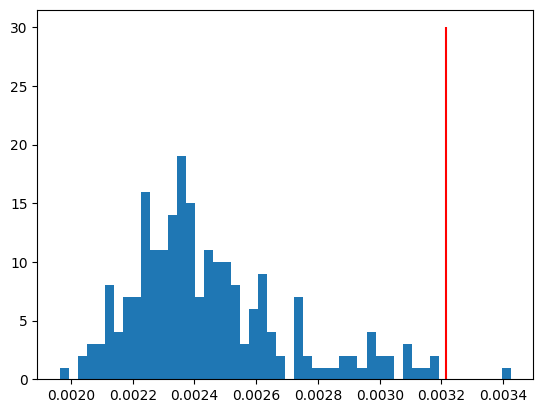

In [38]:
import numpy as np
best_threshold = np.mean(RECON_ERROR) + 3 * np.std(RECON_ERROR)

plt.hist(RECON_ERROR,bins=50)
plt.vlines(x=best_threshold,ymin=0,ymax=30,color='r') 
plt.show()

In [ ]:
y_true=[]
y_pred=[]
y_score=[]

model.eval()

with torch.no_grad():

    test_path = Path('carpet/test')

    for path in test_path.glob('*/*.png'):
        fault_type = path.parts[-2]
        # if fault_type != 'good':
        test_image = transform(Image.fromarray(cv2.read(path)).cuda().unsqueeze(0))
        recon_image = model(test_image)
        
        # y_score_image = 
        y_score_image =  ((test_image - recon_image)**2).mean(axis=(1))[:,0:-10,0:-10].mean()
    
        y_pred_image = 1*(y_score_image >= best_threshold)
        
        y_true_image = 0 if fault_type == 'good' else 1
        
        y_true.append(y_true_image)
        y_pred.append(y_pred_image.cpu())
        y_score.append(y_score_image.cpu())
    
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    y_score = np.array(y_score)
    